# Учебное исследование территории: Высоцкое городское поселение

Это пошаговый ноутбук для исследования территории **Высоцкого городского поселения
(Ленинградская область)** с помощью библиотеки **BlocksNet 1.0.0a9**.

Ноутбук можно запустить **с нуля, сверху вниз**. Исходные данные берутся из папки
`notebooks/better_data` (границы, кварталы, здания, землепользование, дороги, вода,
сервисы и прочие городские объекты).
Для пешеходной доступности одновременно используются дорожный и пешеходный
графы из `notebooks/data/vysokoye`: для каждой пары кварталов берётся лучший
маршрут по любой из сетей при скорости пешехода 5 км/ч.

## Что делает ноутбук
1. Берёт **готовые границы и кварталы** из `better_data`, присваивает устойчивые `block_id`.
2. **Объединяет** слои воды: `lake.geojson` (озёра) + `water.geojson` в один слой.
3. Присваивает кварталам **землепользование** по данным `landuse.geojson`.
4. Считает **пешеходное время в пути между кварталами** одновременно по
   дорожной и пешеходной сети (кратчайший маршрут по любой из них).
5. Агрегирует **здания** и **услуги** по кварталам, сохраняет происхождение ёмкости.
6. Считает плотность, морфотипы, доступность площади, обеспеченность услугами,
   зелёные показатели и доступ к публичной зелени.
7. Сохраняет результаты в `notebooks/data/vysokoye` для дашборда.


## Часть A. Данные и подготовка кварталов

Загружаем подготовленные данные и слои из `better_data`.

### 0. Настройка окружения и папок

Запустите эту ячейку первой.

In [1]:
# ============================================================
# 0. НАСТРОЙКА
# ============================================================
import pickle
import warnings
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd
import osmnx as ox

warnings.filterwarnings("ignore")


def _project_root():
    """Корень проекта (папка с pyproject.toml). Не зависит от места запуска Jupyter."""
    cwd = Path.cwd().resolve()
    for candidate in [cwd, *cwd.parents]:
        if (candidate / "pyproject.toml").exists():
            return candidate
    return cwd.parent if cwd.name == "notebooks" else cwd


PROJECT_ROOT = _project_root()
RESEARCH_DIR = PROJECT_ROOT / "notebooks" / "data" / "vysokoye"
BETTER_DATA_DIR = PROJECT_ROOT / "notebooks" / "better_data"
RESEARCH_DIR.mkdir(parents=True, exist_ok=True)

# Если True — результаты пересчитываются заново (кэш игнорируется)
FORCE_RECALC = False

# Система координат для расчётов (метры). Заполнится после загрузки границ.
CRS = None

print("Корень проекта:", PROJECT_ROOT)
print("Папка результатов:", RESEARCH_DIR)
print("Папка better_data:", BETTER_DATA_DIR)


Корень проекта: C:\TEMPLATE_AI_NIR\python-package-boilerplate
Папка результатов: C:\TEMPLATE_AI_NIR\python-package-boilerplate\notebooks\data\vysokoye
Папка better_data: C:\TEMPLATE_AI_NIR\python-package-boilerplate\notebooks\better_data


### 0.1. Вспомогательные функции

Сохранение результатов в GeoJSON/CSV и чтение как из `better_data`, так и из кэша.

In [2]:
# ============================================================
# 0.1. ВСПОМОГАТЕЛЬНЫЕ ФУНКЦИИ
# ============================================================
def _make_serializable(gdf):
    """Преобразует значения (например, LandUse) в простой текст."""
    gdf = gdf.copy()
    for col in gdf.columns:
        if col != "geometry" and gdf[col].dtype == object:
            gdf[col] = gdf[col].map(lambda v: v.value if hasattr(v, "value") else v)
    return gdf


def save_geojson(gdf, name):
    """Сохраняет слой в notebooks/data/vysokoye (в градусах, как требует GeoJSON)."""
    path = RESEARCH_DIR / f"{name}.geojson"
    out = _make_serializable(gdf)
    if out.crs is not None:
        out = out.to_crs(4326)
    if len(out) == 0:
        print(f"[пусто] {name}: объектов нет, файл не сохранён")
        return path
    try:
        out.to_file(path, driver="GeoJSON")
        print(f"[сохранено] {path.name}: {len(out)} объектов")
    except Exception as exc:  # noqa: BLE001
        print(f"[ошибка сохранения] {name}: {exc}")
    return path


def load_geojson(name):
    """Читает результат из кэша notebooks/data/vysokoye, если он есть."""
    path = RESEARCH_DIR / f"{name}.geojson"
    if not path.exists():
        return None
    gdf = gpd.read_file(path)
    if CRS is not None and gdf.crs is not None:
        gdf = gdf.to_crs(CRS)
    return gdf


def load_better(name):
    """Читает подготовленный вручную слой из папки better_data."""
    path = BETTER_DATA_DIR / f"{name}.geojson"
    if not path.exists():
        raise FileNotFoundError(f"Не найден файл: {path}")
    gdf = gpd.read_file(path).reset_index(drop=True)
    if CRS is not None and gdf.crs is not None:
        gdf = gdf.to_crs(CRS)
    return gdf


def save_graph(graph, name):
    path = RESEARCH_DIR / f"{name}.pickle"
    with open(path, "wb") as f:
        pickle.dump(graph, f)
    print(f"[сохранено] {path.name}")


def load_graph(name):
    path = RESEARCH_DIR / f"{name}.pickle"
    if not path.exists():
        return None
    with open(path, "rb") as f:
        return pickle.load(f)


### 1. Границы территории

Берём готовые границы из `better_data/boundaries.geojson`.
В файле уже есть название и численность населения.


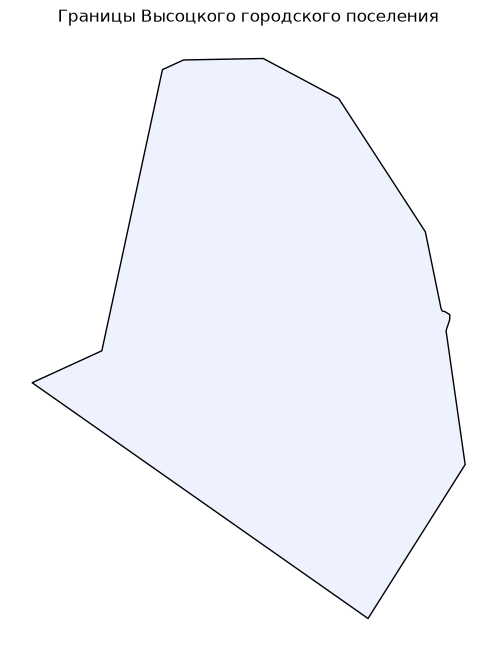

Название: Высоцкое городское поселение
Население (справочно): 1122
CRS для расчётов: EPSG:32635


In [3]:
# ============================================================
# 1. ГРАНИЦЫ ТЕРРИТОРИИ
# ============================================================
boundaries = gpd.read_file(BETTER_DATA_DIR / "boundaries.geojson")
if boundaries.crs is None:
    boundaries = boundaries.set_crs(4326)

# Удобная система координат для расчётов (в метрах)
CRS = boundaries.estimate_utm_crs()
boundaries = boundaries.to_crs(CRS)

ax = boundaries.plot(figsize=(8, 8), facecolor="#eef2ff", edgecolor="black")
ax.set_axis_off()
plt.title("Границы Высоцкого городского поселения")
plt.show()

if "name" in boundaries.columns:
    print("Название:", boundaries["name"].iloc[0])
if "population" in boundaries.columns:
    print("Население (справочно):", int(boundaries["population"].iloc[0]))
print("CRS для расчётов:", CRS)


### 2. Кварталы

Кварталы уже подготовлены вручную — берём их из `better_data/blocks.geojson`.
Резать территорию заново не нужно.


Кварталов: 473
Диапазон block_id: B001 — B473
[сохранено] blocks.geojson: 473 объектов


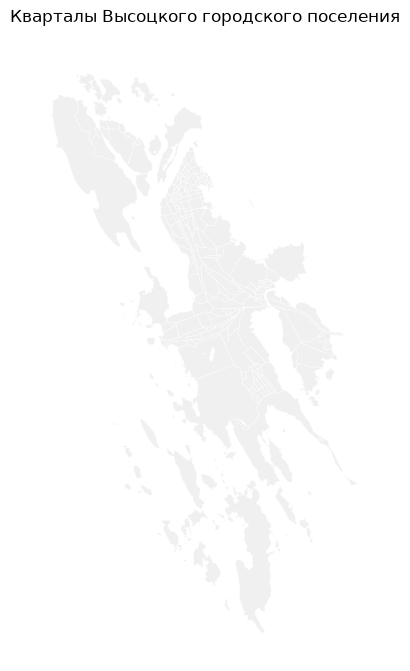

In [4]:
# ============================================================
# 2. КВАРТАЛЫ
# ============================================================
blocks = load_better("blocks").reset_index(drop=True)
blocks = blocks[blocks.geometry.notna() & ~blocks.geometry.is_empty].copy()
blocks = blocks.reset_index(drop=True)

centroids = blocks.geometry.centroid
order = sorted(blocks.index, key=lambda idx: (centroids.loc[idx].y, centroids.loc[idx].x))
blocks = blocks.loc[order].reset_index(drop=True)
blocks["source_index"] = order
blocks["block_id"] = [f"B{index:03d}" for index in range(1, len(blocks) + 1)]

print("Кварталов:", len(blocks))
print("Диапазон block_id:", blocks["block_id"].iloc[0], "—", blocks["block_id"].iloc[-1])

save_geojson(blocks, "blocks")

ax = blocks.plot(figsize=(8, 8), facecolor="#f0f0f0", edgecolor="white", linewidth=0.3)
ax.set_axis_off()
plt.title("Кварталы Высоцкого городского поселения")
plt.show()


### 3. Водные объекты (объединение)

По требованию объединяем **озёра** (`lake.geojson`) и **воду** (`water.geojson`)
в один слой воды. Дороги и железные дороги тоже загружаем — для наглядной карты.


[сохранено] water_merged.geojson: 19 объектов
Озёра: 18 | Вода: 1 | Объединённый слой воды: 19
Дороги: 316 | Железные дороги: 71


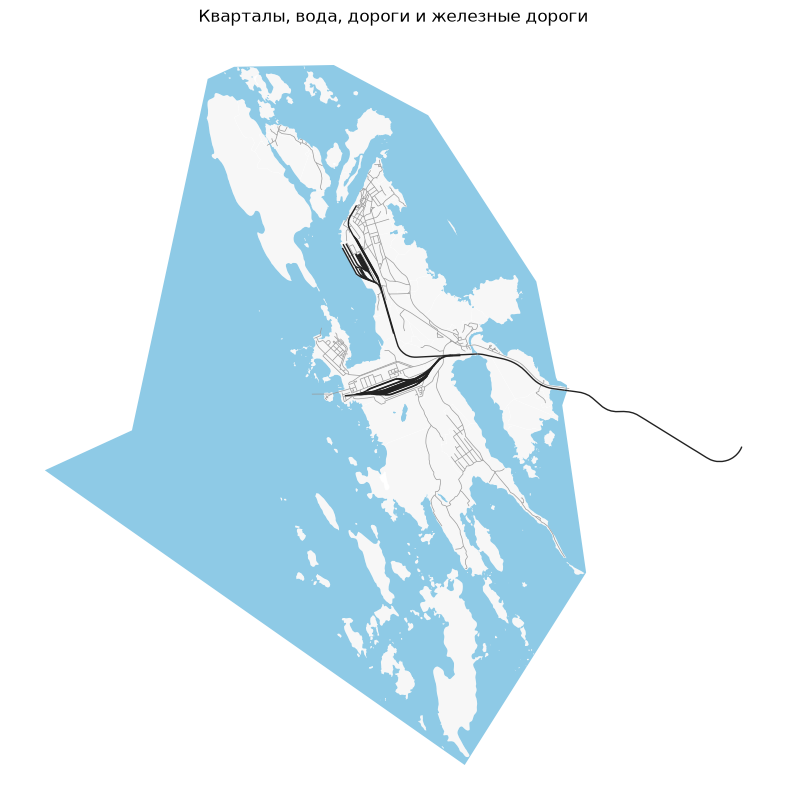

In [5]:
# ============================================================
# 3. ВОДА (озёра + вода) И КОНТЕКСТНЫЕ СЛОИ
# ============================================================
lake = load_better("lake")
water = load_better("water")

water_all = pd.concat([lake[["geometry"]], water[["geometry"]]], ignore_index=True)
water_all = gpd.GeoDataFrame(water_all, geometry="geometry", crs=blocks.crs)
save_geojson(water_all, "water_merged")

print("Озёра:", len(lake), "| Вода:", len(water), "| Объединённый слой воды:", len(water_all))

roads = load_better("roads")
railways = load_better("railways")
print("Дороги:", len(roads), "| Железные дороги:", len(railways))

ax = blocks.plot(figsize=(10, 10), facecolor="#f7f7f7", edgecolor="white", linewidth=0.2)
water_all.plot(ax=ax, color="#8ecae6")
roads.plot(ax=ax, color="#999999", linewidth=0.5)
railways.plot(ax=ax, color="#222222", linewidth=1.0)
ax.set_axis_off()
plt.title("Кварталы, вода, дороги и железные дороги")
plt.show()


### 4. Землепользование кварталов

Берём функциональные зоны из `better_data/landuse.geojson` (столбец `Зона`) и
присваиваем каждому кварталу тип землепользования.


[сохранено] blocks_land_use.geojson: 473 объектов


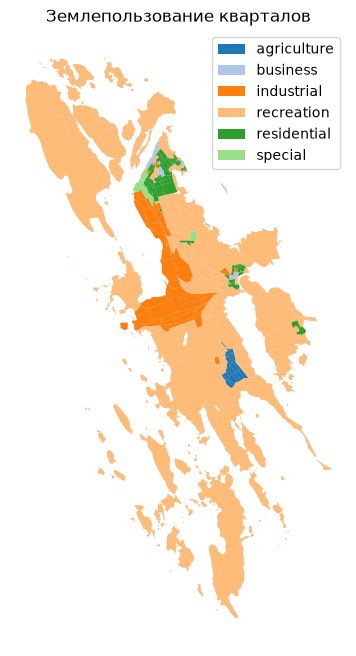

land_use
LandUse.RECREATION     305
LandUse.INDUSTRIAL      63
LandUse.RESIDENTIAL     62
LandUse.AGRICULTURE     21
LandUse.BUSINESS        14
LandUse.SPECIAL          8
Name: count, dtype: int64


In [6]:
# ============================================================
# 4. ЗЕМЛЕПОЛЬЗОВАНИЕ
# ============================================================
from blocksnet.blocks.assignment import assign_land_use
from blocksnet.enums import LandUse

RULES = {
    "Жилая зона": LandUse.RESIDENTIAL,
    "Общественно-деловая зона": LandUse.BUSINESS,
    "Производственная зона, зона инженерной и транспортной инфраструктуры": LandUse.INDUSTRIAL,
    "Зона рекреационного назначения": LandUse.RECREATION,
    "Зона лесопользования": LandUse.RECREATION,
    "Зона сельскохозяйственного использования": LandUse.AGRICULTURE,
    "Зона специального назначения": LandUse.SPECIAL,
    "Зона размещения военных объектов": LandUse.SPECIAL,
    "Водные объекты": LandUse.RECREATION,
}

block_meta = blocks[["block_id", "source_index"]].copy()
fz = load_better("landuse").rename(columns={"Зона": "functional_zone"})
fz = fz[["functional_zone", "geometry"]]

blocks = assign_land_use(blocks, fz, RULES)
blocks = blocks.join(block_meta)
save_geojson(blocks, "blocks_land_use")

blocks_plot = blocks.copy()
blocks_plot["land_use"] = blocks_plot["land_use"].map(
    lambda value: value.value if hasattr(value, "value") else value
)
ax = blocks_plot.plot(figsize=(8, 8), color="#dddddd")
blocks_plot.plot(column="land_use", legend=True, ax=ax, cmap="tab20")
ax.set_axis_off()
plt.title("Землепользование кварталов")
plt.show()
print(blocks["land_use"].value_counts())


---
# ⛔ ОСТАНОВКА

**Кварталы подготовлены.** Дальше начинаются расчёты (граф, здания, услуги, показатели).
Можно спокойно продолжить — все ячейки ниже полностью рабочие.

---

## Часть B. Расчёты показателей


### 5. Графы времени в пути и матрицы доступности

- **Источник графов:** OpenStreetMap (загрузка через IduEdu).
- **Дорожный (`drive`) и пешеходный (`walk`) графы** используются одновременно:
  для каждой пары кварталов берётся кратчайший маршрут по любой из сетей.
- **Пешеходная доступность:** комбинированное расстояние по любой сети при 5 км/ч.
- **Автомобильная доступность:** дорожный граф с весом `time_min`; кварталы
  примыкают к графу по тем же граничным точкам, что и для пешеходной матрицы.
- **Проверка привязки:** расхождение snapped-расстояний с `graph_snap_drive.csv`
  выводится в ячейке и должно быть близко к нулю.


In [7]:
# ============================================================
# 5. ГРАФЫ И МАТРИЦА ПЕШЕХОДНОЙ ДОСТУПНОСТИ (ДОРОГА + ПЕШЕХОДНАЯ СЕТЬ)
# ============================================================
from blocksnet.relations import get_accessibility_graph
from my_package.accessibility import (
    boundary_snap_points,
    calculate_boundary_accessibility_matrix,
    combine_accessibility_matrices,
)

GRAPH_TYPES = ("drive", "walk")
WALK_SPEED_M_PER_MIN = 5000 / 60
graphs = {}
distance_matrices = {}
snap_distances = {}

for graph_type in GRAPH_TYPES:
    graph = None
    if not FORCE_RECALC:
        graph = load_graph(f"graph_{graph_type}")
    if graph is None:
        try:
            graph = get_accessibility_graph(boundaries, graph_type)
            save_graph(graph, f"graph_{graph_type}")
        except Exception as exc:  # noqa: BLE001
            print(f"[ошибка] не удалось построить граф {graph_type}: {exc}")
            continue
    else:
        print(f"[из файла] graph_{graph_type}.pickle")

    graphs[graph_type] = graph
    print(
        "Тип графа:",
        graph_type,
        "| Узлов:",
        graph.number_of_nodes(),
        "| Рёбер:",
        graph.number_of_edges(),
    )

    distance_mx_path = RESEARCH_DIR / f"accessibility_matrix_{graph_type}_boundary_distance.csv"
    snap_path = RESEARCH_DIR / f"graph_snap_{graph_type}.csv"
    if not FORCE_RECALC and distance_mx_path.exists() and snap_path.exists():
        distance_mx = pd.read_csv(distance_mx_path, index_col=0)
        distance_mx.index = distance_mx.index.astype(int)
        distance_mx.columns = distance_mx.columns.astype(int)
        snap = pd.read_csv(snap_path, index_col=0).iloc[:, 0]
        snap.index = snap.index.astype(int)
        print(f"[из файла] accessibility_matrix_{graph_type}_boundary_distance.csv")
    else:
        distance_mx, snap = calculate_boundary_accessibility_matrix(
            blocks,
            graph,
            weight_key="length_meter",
        )
        distance_mx.to_csv(distance_mx_path)
        snap.rename("snap_distance_m").to_frame().to_csv(snap_path)
        print(f"[сохранено] accessibility_matrix_{graph_type}_boundary_distance.csv")

    distance_matrices[graph_type] = distance_mx
    snap_distances[graph_type] = snap
    print(
        "Привязка к графу:",
        "медиана",
        round(float(snap.median()), 1),
        "м | p90",
        round(float(snap.quantile(0.9)), 1),
        "м | максимум",
        round(float(snap.max()), 1),
        "м",
    )

if not distance_matrices:
    raise RuntimeError("Не удалось построить ни один граф доступности")

# Пешеход может идти по любой сети: для каждой пары кварталов берём минимум расстояния.
distance_mx = combine_accessibility_matrices(distance_matrices)
distance_mx.to_csv(RESEARCH_DIR / "accessibility_matrix_boundary_distance_any.csv")
acc_mx = distance_mx / WALK_SPEED_M_PER_MIN
acc_mx.to_csv(RESEARCH_DIR / "accessibility_matrix_pedestrian.csv")

# Автомобильная доступность: тот же квартальный слой и то же примыкание к графу,
# но вес рёбер — time_min из дорожного графа.
drive_time_path = RESEARCH_DIR / "accessibility_matrix_drive.csv"
drive_graph = graphs.get("drive")
if drive_graph is not None:
    if drive_time_path.exists() and not FORCE_RECALC:
        drive_time_mx = pd.read_csv(drive_time_path, index_col=0)
        drive_time_mx.index = drive_time_mx.index.astype(int)
        drive_time_mx.columns = drive_time_mx.columns.astype(int)
        _, drive_time_snap = boundary_snap_points(blocks, drive_graph)
        print(f"[из файла] {drive_time_path.name}")
    else:
        drive_time_mx, drive_time_snap = calculate_boundary_accessibility_matrix(
            blocks,
            drive_graph,
            weight_key="time_min",
        )
        drive_time_mx.to_csv(drive_time_path)
        print(f"[сохранено] {drive_time_path.name}")
    snap_diff = (drive_time_snap - snap_distances["drive"]).abs().max()
    print(
        "[проверка] авто-доступность: max |Δ привязки кварталов к графу| =",
        round(float(snap_diff), 6),
        "м",
    )

snap_df = pd.DataFrame(snap_distances)
snap_df.to_csv(RESEARCH_DIR / "graph_snap_distance.csv")
print(
    "[сохранено] accessibility_matrix_pedestrian.csv:",
    acc_mx.shape,
    "| сети:",
    ", ".join(distance_matrices),
)
print("Скорость пешехода:", round(WALK_SPEED_M_PER_MIN, 2), "м/мин (5 км/ч)")
acc_mx.head()


[из файла] graph_drive.pickle
Тип графа: drive | Узлов: 120 | Рёбер: 304
[из файла] accessibility_matrix_drive_boundary_distance.csv
Привязка к графу: медиана 465.2 м | p90 3622.8 м | максимум 5914.4 м
[из файла] graph_walk.pickle
Тип графа: walk | Узлов: 607 | Рёбер: 1644
[из файла] accessibility_matrix_walk_boundary_distance.csv
Привязка к графу: медиана 127.0 м | p90 2290.3 м | максимум 3821.1 м


[сохранено] accessibility_matrix_pedestrian.csv: (473, 473) | сети: drive, walk
Скорость пешехода: 83.33 м/мин (5 км/ч)


,0,1,2,3,4,5,6,7,8,9,...,463,464,465,466,467,468,469,470,471,472
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,206.725172,206.603344,206.721094,205.512984,205.596656,197.343047,206.002172,205.737258,206.169984,206.025656
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,199.480125,199.358273,199.476023,198.267914,198.351609,190.098000,198.757102,198.492188,198.924914,198.780586
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,198.508805,198.386953,198.504703,197.296594,197.380289,189.126680,197.785781,197.520867,197.953594,197.809266
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,197.642391,197.520539,197.638289,196.430180,196.513875,188.260266,196.919367,196.654453,197.087180,196.942852
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,184.307203,184.185363,184.303125,183.095004,183.178688,174.925090,183.584203,183.319289,183.752016,183.607687


### 6. Здания и население по кварталам

Здания берём из `better_data/building.geojson` (там уже есть этажность,
площади и население). Недостающие значения дозаполняются, затем данные
суммируются по кварталам.


2026-10-28 18:54:38.236 | INFO     | blocksnet.blocks.aggregation.core:_preprocess_input:12 - Preprocessing input


2026-10-28 18:54:38.238 | INFO     | blocksnet.blocks.aggregation.core:aggregate_objects:41 - Aggregating objects


[сохранено] buildings_blocks.geojson: 473 объектов
Кварталов со зданиями: 473


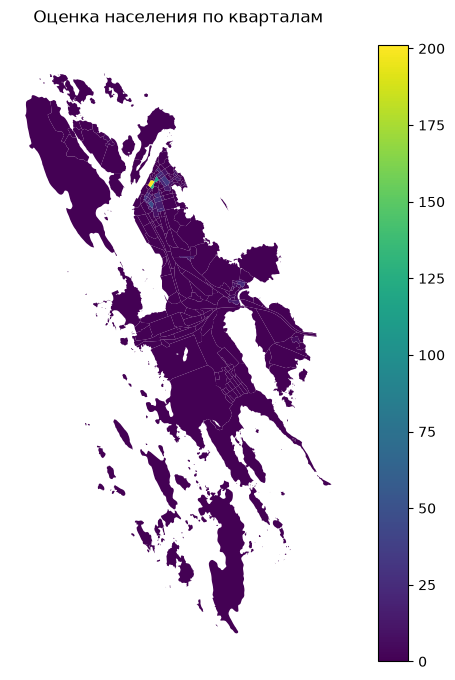

Суммарная оценка населения: 1135


In [8]:
# ============================================================
# 6. ЗДАНИЯ (агрегация по кварталам)
# ============================================================
from blocksnet.preprocessing.imputing import impute_buildings
from blocksnet.blocks.aggregation import aggregate_objects

b = load_better("building")
b["is_living"] = b["is_living"].astype(bool)
b = impute_buildings(b, default_living_demand=30)

buildings_blocks = aggregate_objects(blocks, b)[0]
save_geojson(buildings_blocks, "buildings_blocks")
print("Кварталов со зданиями:", len(buildings_blocks))

# Площадь квартала нужна для показателей плотности
buildings_blocks["site_area"] = buildings_blocks.area

buildings_blocks.plot("population", legend=True, figsize=(8, 8)).set_axis_off()
plt.title("Оценка населения по кварталам")
plt.show()
print("Суммарная оценка населения:", int(buildings_blocks["population"].sum()))


### 7. Сервисы и ёмкость

Сервисы загружаются из `better_data/services`: исходные GeoJSON и ёмкость объектов.
Если исходная ёмкость отсутствует, она оценивается по площади объекта или по
нормативному типу BlocksNet. Для магазинов и супермаркетов используются повышенные
нормативные значения, чтобы не занижать их вклад. Источник значения сохраняется в
`capacity_source`: `source`, `area`, `override` или `type`.

Ёмкость агрегируется по кварталам в `services_blocks.geojson`.
Для взаимозаменяемых сервисов считаются комбинированные ёмкости:
продукты (супермаркеты + магазины у дома) и парки (парки + заповедники).

Для каждого сервиса в итоговый слой добавляются `access_time_*` (время до ближайшего
объекта), `service_demand_*` (нормативный спрос), `service_served_*` (ожидаемое число
пользователей) и `service_capacity_*` (ёмкость объектов в квартале).


In [9]:
# ============================================================
# 7. СЕРВИСЫ (из better_data/services)
# ============================================================
from blocksnet.config import service_types_config
from my_package.service_catalog import (
    SERVICE_ALIASES,
    SERVICE_CONTEXT_ONLY,
    SERVICE_LABELS,
    list_service_files as list_catalog_service_files,
    load_service_layer,
)

SERVICES_DIR = BETTER_DATA_DIR / "services"
service_files = list_catalog_service_files(SERVICES_DIR)
for context_id in sorted(SERVICE_CONTEXT_ONLY):
    if (SERVICES_DIR / f"{context_id}.geojson").exists():
        print(f"[контекст] {context_id}: слой показывается, обеспеченность не считается")

service_path = RESEARCH_DIR / "services_blocks.geojson"
expected_columns = {f"capacity_{service_id}" for service_id in service_files}

cache_is_fresh = (
    not FORCE_RECALC
    and service_path.exists()
    and all(
        service_path.stat().st_mtime >= path.stat().st_mtime
        for path, _ in service_files.values()
    )
)

if cache_is_fresh:
    services_blocks = load_geojson("services_blocks").reset_index(drop=True)
    existing_columns = {c for c in services_blocks.columns if c.startswith("capacity_")}
    if existing_columns != expected_columns:
        cache_is_fresh = False
        print("[пересчет] состав сервисов изменился")

if cache_is_fresh:
    print("[из кеша] services_blocks.geojson")
else:
    services_blocks = blocks[["block_id", "geometry"]].copy()
    for service_id, (path, service_type) in service_files.items():
        gdf = load_service_layer(path, service_id, crs=CRS)
        if len(gdf) == 0:
            print(f"{SERVICE_LABELS.get(service_id, service_id)}: нет объектов")
            continue
        sources = gdf["capacity_source"].value_counts().to_dict()
        agg = aggregate_objects(blocks, gdf)[0]
        services_blocks[f"capacity_{service_id}"] = (
            agg["capacity"].reindex(services_blocks.index).fillna(0)
        )
        print(
            f"{SERVICE_LABELS.get(service_id, service_id)}: "
            f"{len(gdf)} объектов; ёмкость: {sources}"
        )
    for service_id in service_files:
        col = f"capacity_{service_id}"
        if col not in services_blocks.columns:
            services_blocks[col] = 0.0
    save_geojson(services_blocks, "services_blocks")

print("Capacity-колонки:", [c for c in services_blocks.columns if c.startswith("capacity_")])


2026-10-28 18:54:38.622 | INFO     | blocksnet.blocks.aggregation.core:_preprocess_input:12 - Preprocessing input


2026-10-28 18:54:38.623 | INFO     | blocksnet.blocks.aggregation.core:aggregate_objects:41 - Aggregating objects


2026-10-28 18:54:38.647 | INFO     | blocksnet.blocks.aggregation.core:_preprocess_input:12 - Preprocessing input


2026-10-28 18:54:38.649 | INFO     | blocksnet.blocks.aggregation.core:aggregate_objects:41 - Aggregating objects


2026-10-28 18:54:38.678 | INFO     | blocksnet.blocks.aggregation.core:_preprocess_input:12 - Preprocessing input


2026-10-28 18:54:38.679 | INFO     | blocksnet.blocks.aggregation.core:aggregate_objects:41 - Aggregating objects


... (54 outputs left out)

2026-10-28 18:54:39.451 | INFO     | blocksnet.blocks.aggregation.core:_preprocess_input:12 - Preprocessing input


2026-10-28 18:54:39.452 | INFO     | blocksnet.blocks.aggregation.core:aggregate_objects:41 - Aggregating objects


Подстанции: 4 объектов; ёмкость: {'type': 4}
Супермаркеты: 1 объектов; ёмкость: {'override': 1}
Ж/д здания: 1 объектов; ёмкость: {'type': 1}
Ж/д станции: 1 объектов; ёмкость: {'type': 1}
Зоопарки: 1 объектов; ёмкость: {'area': 1}


[сохранено] services_blocks.geojson: 473 объектов
Capacity-колонки: ['capacity_bank', 'capacity_beach', 'capacity_boilerhouse', 'capacity_bus_stop', 'capacity_cafe', 'capacity_camp', 'capacity_cemetery', 'capacity_convenience', 'capacity_embankment', 'capacity_energy', 'capacity_fire_station', 'capacity_kindergarten', 'capacity_library', 'capacity_mfz', 'capacity_outpost', 'capacity_park', 'capacity_parking', 'capacity_pier', 'capacity_port', 'capacity_post_office', 'capacity_religion', 'capacity_reserve', 'capacity_school', 'capacity_stadium', 'capacity_substation', 'capacity_supermarket', 'capacity_train_building', 'capacity_train_station', 'capacity_zoo']


### 8. Показатели плотности и морфотипы

Считаем показатели плотности застройки и определяем морфотипы (Spacematrix и Strelka).

In [10]:
# ============================================================
# 8. ПЛОТНОСТЬ И МОРФОТИПЫ
# ============================================================
from blocksnet.analysis.indicators import calculate_density_indicators
from blocksnet.analysis.morphotypes import get_spacematrix_morphotypes, get_strelka_morphotypes

density_df = calculate_density_indicators(buildings_blocks)
print("Показатели плотности:", list(density_df.columns))

spacematrix_df, spacematrix_clusters = None, None
try:
    spacematrix_df, spacematrix_clusters = get_spacematrix_morphotypes(density_df)
    print("Spacematrix-морфотипы построены")
except Exception as exc:  # noqa: BLE001
    print("Не удалось построить Spacematrix-морфотипы:", exc)

strelka_df = None
try:
    strelka_df = get_strelka_morphotypes(density_df)
    print("Strelka-морфотипы построены")
except Exception as exc:  # noqa: BLE001
    print("Не удалось построить Strelka-морфотипы:", exc)

density_df.head()


Показатели плотности: ['site_area', 'footprint_area', 'build_floor_area', 'living_area', 'non_living_area', 'fsi', 'gsi', 'mxi', 'l', 'osr', 'share_living', 'share_non_living']


Spacematrix-морфотипы построены
Strelka-морфотипы построены


,site_area,footprint_area,build_floor_area,living_area,non_living_area,fsi,gsi,mxi,l,osr,share_living,share_non_living
0,996.672467,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,inf,NaN,NaN
1,19459.684554,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,inf,NaN,NaN
2,71.523370,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,inf,NaN,NaN
3,829.159049,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,inf,NaN,NaN
4,338981.783536,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,inf,NaN,NaN


### 9. Доступность площади кварталов

Считаем, какая площадь кварталов доступна в пределах заданного времени (по матрице доступности).

Столбцы: ['area_accessibility']


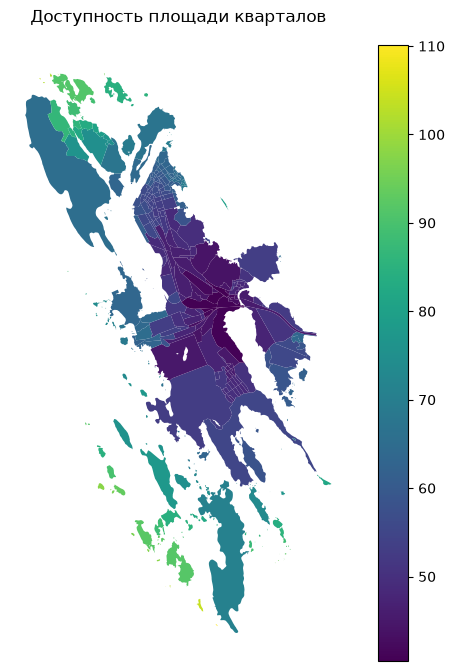

In [11]:
# ============================================================
# 9. ДОСТУПНОСТЬ ПЛОЩАДИ
# ============================================================
from blocksnet.analysis.network import area_accessibility

area_acc = area_accessibility(acc_mx, buildings_blocks)
print("Столбцы:", list(area_acc.columns))

blocks.join(area_acc).plot("area_accessibility", legend=True, figsize=(8, 8)).set_axis_off()
plt.title("Доступность площади кварталов")
plt.show()


### 9.1. Озеленение, лес и доступ к публичной зелени

Считаем в проекции UTM:

- `forest_share` — доля квартала под слоем `forest.geojson`;
- `park_share` — доля под `park.geojson`;
- `green_share` — доля под объединением forest + park + зелёные типы landuse;
- `green_m2_per_capita` — зелёная площадь на человека (только при населении > 0);
- `green_access_m` — расстояние до публичной зелени по дорожной или пешеходной
  сети (парки + landuse «Зеленые насаждения общего пользования»).

Геометрии чинятся через `make_valid`, слои объединяются через `unary_union`,
чтобы не было двойного счёта. `forest_share` — это земной покров, а не доказательство
доступности леса для жителей.


In [12]:
# ============================================================
# 9.1. ОЗЕЛЕНЕНИЕ, ЛЕС И ДОСТУП К ПУБЛИЧНОЙ ЗЕЛЕНИ
# ============================================================
import networkx as nx
import numpy as np
from shapely.ops import unary_union
from shapely.validation import make_valid

from my_package.accessibility import combine_distance_series

GREEN_LANDUSE_MARKERS = (
    "зона лесопользования",
    "зеленые насаждения общего пользования",
    "зеленые насаждения санитарно-защитной зоны",
    "зеленые насаждения водоохранных зон",
)
PUBLIC_GREEN_MARKERS = ("зеленые насаждения общего пользования",)


def _valid_geometry(geometry):
    if geometry is None or geometry.is_empty:
        return None
    if not geometry.is_valid:
        geometry = make_valid(geometry)
    if geometry.is_empty:
        return None
    return geometry


def _valid_union(gdf):
    geometries = [_valid_geometry(geometry) for geometry in gdf.geometry]
    geometries = [geometry for geometry in geometries if geometry is not None]
    if not geometries:
        return None
    return unary_union(geometries)


def _union_all(geometries):
    geometries = [
        geometry
        for geometry in geometries
        if geometry is not None and not geometry.is_empty
    ]
    if not geometries:
        return None
    return unary_union(geometries)


def _intersection_area(blocks_gdf, geometry):
    if geometry is None or geometry.is_empty:
        return pd.Series(0.0, index=blocks_gdf.index)
    return blocks_gdf.geometry.intersection(geometry).area.fillna(0.0)


def _polygon_parts(geometry):
    if geometry is None or geometry.is_empty:
        return []
    if geometry.geom_type == "Polygon":
        return [geometry]
    if geometry.geom_type == "MultiPolygon":
        return list(geometry.geoms)
    if hasattr(geometry, "geoms"):
        parts = []
        for part in geometry.geoms:
            parts.extend(_polygon_parts(part))
        return parts
    return []


def _boundary_nodes(graph, geometry, step=50.0):
    nodes = []
    for polygon in _polygon_parts(geometry):
        line = polygon.exterior
        if line.length <= 0:
            continue
        distances = np.arange(0.0, line.length, step)
        points = [line.interpolate(min(distance, line.length)) for distance in distances]
        if not points:
            continue
        nearest = ox.distance.nearest_nodes(
            graph,
            X=np.array([point.x for point in points]),
            Y=np.array([point.y for point in points]),
        )
        nodes.extend(np.atleast_1d(nearest).tolist())
    return sorted({int(node) for node in nodes})


landuse_gdf = load_better("landuse")
if "Тип" not in landuse_gdf.columns:
    raise KeyError("В landuse.geojson нет колонки 'Тип'")
normalized_types = landuse_gdf["Тип"].fillna("").astype(str).str.lower()
green_landuse_mask = normalized_types.apply(
    lambda value: any(marker in value for marker in GREEN_LANDUSE_MARKERS)
)
public_green_mask = normalized_types.apply(
    lambda value: any(marker in value for marker in PUBLIC_GREEN_MARKERS)
)

forest_gdf = load_better("services/forest")
park_gdf = load_better("services/park")
green_landuse_gdf = landuse_gdf[green_landuse_mask]
public_green_landuse_gdf = landuse_gdf[public_green_mask]

forest_union = _valid_union(forest_gdf)
park_union = _valid_union(park_gdf)
landuse_green_union = _valid_union(green_landuse_gdf)
public_green_landuse_union = _valid_union(public_green_landuse_gdf)

green_union = _union_all([forest_union, park_union, landuse_green_union])
public_green_union = _union_all([park_union, public_green_landuse_union])

blocks_for_green = blocks.copy()
blocks_for_green["geometry"] = blocks_for_green.geometry.map(_valid_geometry)
blocks_for_green = blocks_for_green[blocks_for_green.geometry.notna()].copy()
block_area = blocks_for_green.geometry.area.replace(0, np.nan)

green_df = pd.DataFrame(index=blocks.index)
green_area = _intersection_area(blocks_for_green, green_union)
forest_area = _intersection_area(blocks_for_green, forest_union)
park_area = _intersection_area(blocks_for_green, park_union)
green_df["forest_share"] = (forest_area / block_area).reindex(blocks.index).fillna(0.0).clip(0.0, 1.0)
green_df["park_share"] = (park_area / block_area).reindex(blocks.index).fillna(0.0).clip(0.0, 1.0)
green_df["green_share"] = (green_area / block_area).reindex(blocks.index).fillna(0.0).clip(0.0, 1.0)
green_df["green_area_m2"] = green_area.reindex(blocks.index).fillna(0.0)

population = pd.to_numeric(
    buildings_blocks["population"].reindex(blocks.index),
    errors="coerce",
)
green_df["green_m2_per_capita"] = np.where(
    population > 0,
    green_df["green_area_m2"] / population,
    np.nan,
)

green_access = pd.Series(np.nan, index=blocks.index, dtype=float)
if graphs and public_green_union is not None:
    public_green_parts = _polygon_parts(public_green_union)
    if public_green_parts:
        centroids = blocks_for_green.geometry.centroid
        network_distances = {}
        for graph_type, graph in graphs.items():
            if graph is None:
                continue
            destination_nodes = _boundary_nodes(graph, public_green_union)
            if not destination_nodes:
                continue
            distances = nx.multi_source_dijkstra_path_length(
                graph.to_undirected(),
                destination_nodes,
                weight="length_meter",
            )
            origin_nodes = ox.distance.nearest_nodes(
                graph,
                X=centroids.x.to_numpy(),
                Y=centroids.y.to_numpy(),
            )
            network_distances[graph_type] = pd.Series(
                [
                    distances.get(int(node), np.nan)
                    for node in np.atleast_1d(origin_nodes)
                ],
                index=blocks_for_green.index,
                dtype=float,
            )
        if network_distances:
            green_access.loc[blocks_for_green.index] = combine_distance_series(
                network_distances
            )

green_df["green_access_m"] = green_access
green_df["green_access_500"] = np.where(
    green_access.notna(),
    (green_access <= 500).astype(float),
    np.nan,
)

print("Зелёные полигоны landuse:", len(green_landuse_gdf))
print("Публичная зелень: park + landuse общего пользования; доступ по любой сети (drive + walk)")
print("green_share: median =", round(green_df["green_share"].median(), 3))
print("green_share = 0:", int((green_df["green_share"] <= 0).sum()))
print("green_share = 1:", int((green_df["green_share"] >= 0.999999).sum()))
print("green_access_m: n =", int(green_df["green_access_m"].notna().sum()))
print("green_access_500 = 1:", int((green_df["green_access_500"].fillna(0) == 1).sum()))
green_df.head()


Зелёные полигоны landuse: 160
Публичная зелень: park + landuse общего пользования; доступ по любой сети (drive + walk)
green_share: median = 0.463
green_share = 0: 160
green_share = 1: 183
green_access_m: n = 473
green_access_500 = 1: 218


,forest_share,park_share,green_share,green_area_m2,green_m2_per_capita,green_access_m,green_access_500
0,0.0,0.0,1.0,996.672467,NaN,1214.416,0.0
1,1.0,0.0,1.0,19459.684554,NaN,1214.416,0.0
2,1.0,0.0,1.0,71.523370,NaN,1214.416,0.0
3,1.0,0.0,1.0,829.159049,NaN,1214.416,0.0
4,1.0,0.0,1.0,338981.783536,NaN,1214.416,0.0


### 10. Вероятностная обеспеченность услугами

Вместо жёсткого порога доступности используется гравитационная модель (Huff).
Вероятность пользоваться сервисом плавно убывает с временем в пути:

`p_use = 0.5 ** (time / half_life)`, где `half_life = 0.75 * accessibility`.

Выбор между объектами пропорционален `capacity * p_use`. Затем ожидаемая нагрузка
ограничивается ёмкостью каждого объекта. Поэтому нет резкой границы «доступно /
недоступно»: число пользователей меняется постепенно, а расстояние имеет большой вес.

Сохраняются оба варианта: `provision_strong` (с учётом ёмкости) и `provision_weak`
(без ограничения ёмкости). Дополнительно считаются комбинированные индексы:

- **продукты** — супермаркеты + магазины у дома, норматив супермаркета;
- **парки** — парки + заповедники, норматив парка.


In [13]:
# ============================================================
# 10. ВЕРОЯТНОСТНАЯ ОБЕСПЕЧЕННОСТЬ УСЛУГАМИ
# ============================================================
from blocksnet.config import service_types_config
from my_package.provision import probabilistic_provision
from my_package.service_catalog import PROVISION_COMBINATIONS

provision_results = {}
service_metrics = {}


def _service_metrics(service_id, capacity, prov_df):
    capacity = capacity.reindex(acc_mx.index).fillna(0).astype(float)
    return pd.DataFrame(
        {
            f"access_time_{service_id}": prov_df["access_time"],
            f"service_demand_{service_id}": prov_df["demand"],
            f"service_served_{service_id}": prov_df["demand_within"],
            f"service_capacity_{service_id}": capacity,
        }
    )


for service_id, (_, service_type) in service_files.items():
    col = f"capacity_{service_id}"
    if col not in services_blocks.columns:
        continue
    capacity = services_blocks[col].reindex(acc_mx.index).fillna(0)
    df = buildings_blocks[["population"]].join(capacity.rename("capacity"))
    demand = service_types_config[service_type]["demand"]
    accessibility = service_types_config[service_type]["accessibility"]
    prov_df = probabilistic_provision(df, acc_mx, accessibility, demand)
    provision_results[service_id] = prov_df[["provision_strong", "provision_weak"]]
    service_metrics[service_id] = _service_metrics(service_id, capacity, prov_df)
    label = SERVICE_LABELS.get(service_id, service_id)
    print(f"{label}: средняя обеспеченность = {prov_df['provision_strong'].mean():.2f}")

for combination in PROVISION_COMBINATIONS:
    component_cols = [
        f"capacity_{component}"
        for component in combination["components"]
        if f"capacity_{component}" in services_blocks.columns
    ]
    if not component_cols:
        print(f"[пропуск] {combination['id']}: нет компонентов")
        continue
    capacity = services_blocks[component_cols].sum(axis=1)
    df = buildings_blocks[["population"]].join(capacity.rename("capacity"))
    norm_type = combination["norm_service"]
    demand = service_types_config[norm_type]["demand"]
    accessibility = service_types_config[norm_type]["accessibility"]
    prov_df = probabilistic_provision(df, acc_mx, accessibility, demand)
    provision_results[combination["id"]] = prov_df[["provision_strong", "provision_weak"]]
    service_metrics[combination["id"]] = _service_metrics(combination["id"], capacity, prov_df)
    SERVICE_LABELS[combination["id"]] = combination["short_label"]
    print(
        f"{combination['short_label']}: средняя обеспеченность = "
        f"{prov_df['provision_strong'].mean():.2f} "
        f"({', '.join(combination['components'])}; норматив {norm_type})"
    )

list(provision_results)


Банки: средняя обеспеченность = 0.66
Пляжи: средняя обеспеченность = 0.75
Котельные: средняя обеспеченность = 0.79
Остановки: средняя обеспеченность = 0.59
Кафе: средняя обеспеченность = 0.56
Детские лагеря: средняя обеспеченность = 0.72
Кладбища: средняя обеспеченность = 0.77
Магазины у дома: средняя обеспеченность = 0.32
Набережные: средняя обеспеченность = 0.64
Электроснабжение: средняя обеспеченность = 0.44
Пожарные станции: средняя обеспеченность = 0.79
Детские сады: средняя обеспеченность = 0.33
Библиотеки: средняя обеспеченность = 0.64
МФЦ: средняя обеспеченность = 0.55
Пункты полиции: средняя обеспеченность = 0.55
Парки: средняя обеспеченность = 0.72
Парковки: средняя обеспеченность = 0.76
Причалы: средняя обеспеченность = 0.82
Порты: средняя обеспеченность = 0.74
Почтовые отделения: средняя обеспеченность = 0.53


Религиозные объекты: средняя обеспеченность = 0.64


Заповедники: средняя обеспеченность = 0.47
Школы: средняя обеспеченность = 0.52
Стадионы: средняя обеспеченность = 0.75
Подстанции: средняя обеспеченность = 0.36
Супермаркеты: средняя обеспеченность = 0.50
Ж/д здания: средняя обеспеченность = 0.75
Ж/д станции: средняя обеспеченность = 0.65
Зоопарки: средняя обеспеченность = 0.53
Продукты (комб.): средняя обеспеченность = 0.54 (supermarket, convenience; норматив supermarket)
Парки (комб.): средняя обеспеченность = 0.72 (park, reserve; норматив park)


['bank',
 'beach',
 'boilerhouse',
 'bus_stop',
 'cafe',
 'camp',
 'cemetery',
 'convenience',
 'embankment',
 'energy',
 'fire_station',
 'kindergarten',
 'library',
 'mfz',
 'outpost',
 'park',
 'parking',
 'pier',
 'port',
 'post_office',
 'religion',
 'reserve',
 'school',
 'stadium',
 'substation',
 'supermarket',
 'train_building',
 'train_station',
 'zoo',
 'grocery',
 'parks']

### 11. Сборка итоговой таблицы результатов

Соединяем показатели по кварталам в один слой и сохраняем в `results.geojson`:
`block_id`, население, морфологию, доступность, зелёные показатели и доступ к зелени,
сильную и слабую обеспеченность, включая комбинированные индексы. Дополнительно
сохраняются расстояния привязки кварталов к графам `graph_snap_*_m`.


In [14]:
# ============================================================
# 11. ИТОГОВЫЙ СЛОЙ РЕЗУЛЬТАТОВ
# ============================================================
results = blocks[[c for c in blocks.columns if c != "land_use"]].copy()
if "land_use" in blocks.columns:
    results["land_use"] = blocks["land_use"].astype(str)
results = results.join(buildings_blocks[["population"]])
results = results.join(
    density_df[["fsi", "gsi", "mxi", "l", "osr", "share_living", "share_non_living"]]
)
if spacematrix_df is not None:
    results = results.join(
        spacematrix_df[["morphotype"]].rename(
            columns={"morphotype": "spacematrix_morphotype"}
        )
    )
if strelka_df is not None:
    results = results.join(
        strelka_df[["morphotype"]].rename(columns={"morphotype": "strelka_morphotype"})
    )
results = results.join(
    green_df[
        [
            "forest_share",
            "park_share",
            "green_share",
            "green_area_m2",
            "green_m2_per_capita",
            "green_access_m",
            "green_access_500",
        ]
    ]
)
results = results.join(area_acc[["area_accessibility"]])
for service_id, pdf in provision_results.items():
    results[f"provision_strong_{service_id}"] = pdf["provision_strong"]
    results[f"provision_weak_{service_id}"] = pdf["provision_weak"]
for service_id, metrics in service_metrics.items():
    results = results.join(metrics)
results["osr"] = pd.to_numeric(results["osr"], errors="coerce").replace(
    [float("inf"), float("-inf")], float("nan")
)
results["has_building"] = results["osr"].notna()
results["has_population"] = pd.to_numeric(results["population"], errors="coerce").fillna(0) > 0
for graph_type, snap in snap_distances.items():
    results[f"graph_snap_{graph_type}_m"] = snap.reindex(results.index).astype(float)



save_geojson(results, "results")
print("Столбцы итогового слоя:", list(results.columns))
results.head()


[сохранено] results.geojson: 473 объектов
Столбцы итогового слоя: ['geometry', 'residential', 'business', 'recreation', 'industrial', 'transport', 'special', 'agriculture', 'share', 'block_id', 'source_index', 'land_use', 'population', 'fsi', 'gsi', 'mxi', 'l', 'osr', 'share_living', 'share_non_living', 'spacematrix_morphotype', 'strelka_morphotype', 'forest_share', 'park_share', 'green_share', 'green_area_m2', 'green_m2_per_capita', 'green_access_m', 'green_access_500', 'area_accessibility', 'provision_strong_bank', 'provision_weak_bank', 'provision_strong_beach', 'provision_weak_beach', 'provision_strong_boilerhouse', 'provision_weak_boilerhouse', 'provision_strong_bus_stop', 'provision_weak_bus_stop', 'provision_strong_cafe', 'provision_weak_cafe', 'provision_strong_camp', 'provision_weak_camp', 'provision_strong_cemetery', 'provision_weak_cemetery', 'provision_strong_convenience', 'provision_weak_convenience', 'provision_strong_embankment', 'provision_weak_embankment', 'provision_s

,geometry,residential,business,recreation,industrial,transport,special,agriculture,share,block_id,...,service_served_grocery,service_capacity_grocery,access_time_parks,service_demand_parks,service_served_parks,service_capacity_parks,has_building,has_population,graph_snap_drive_m,graph_snap_walk_m
0,"POLYGON ((587463.073 6710884.37, 587467.098 67...",0.0,0.0,1.000000,0.0,0.0,0.0,0.0,1.000000,B001,...,0.0,0.0,151.874437,0.0,0.0,0.0,False,False,5914.412983,3821.100798
1,"POLYGON ((587061.971 6711257.549, 587059.409 6...",0.0,0.0,0.999993,0.0,0.0,0.0,0.0,0.999993,B002,...,0.0,0.0,144.629379,0.0,0.0,0.0,False,False,5310.658150,3258.683784
2,"POLYGON ((586126.904 6711879.96, 586112.639 67...",0.0,0.0,1.000000,0.0,0.0,0.0,0.0,1.000000,B003,...,0.0,0.0,143.658059,0.0,0.0,0.0,False,False,5229.714675,3338.096714
3,"POLYGON ((586234.671 6711897.296, 586232.989 6...",0.0,0.0,1.000000,0.0,0.0,0.0,0.0,1.000000,B004,...,0.0,0.0,142.791645,0.0,0.0,0.0,False,False,5157.513573,3246.283522
4,"POLYGON ((586709.55 6711962.252, 586715.153 67...",0.0,0.0,0.999883,0.0,0.0,0.0,0.0,0.999883,B005,...,0.0,0.0,129.456469,0.0,0.0,0.0,False,False,4046.248824,2256.558371


### 12. Проверка результатов

Проверяем `block_id`, зелёные доли, доступ к зелени, пропуски и корреляции OSR ↔ зелёные
показатели для трёх вселенных. Для каждой корреляции печатаются `n` и метод.


Кварталов: 473
block_id: B001 — B473
Кварталов со зданиями: 145
Кварталов с населением: 56
Матрица доступности (любая сеть): (473, 473) -> 473 кварталов
Всего населения (оценка): 1135

Пропуски в итоговом слое:
green_m2_per_capita              417
provision_strong_library         417
provision_weak_mfz               417
provision_strong_mfz             417
provision_weak_fire_station      417
provision_strong_fire_station    417
provision_weak_energy            417
provision_strong_energy          417
provision_weak_embankment        417
provision_strong_embankment      417
provision_weak_kindergarten      417
provision_strong_kindergarten    417
dtype: int64

green_share: n=473, min=0.000, median=0.463, max=1.000
  вне [0, 1]: 0
forest_share: n=473, min=0.000, median=0.000, max=1.000
  вне [0, 1]: 0
park_share: n=473, min=0.000, median=0.000, max=0.911
  вне [0, 1]: 0
green_share = 0: 160
green_share = 1: 183
green_m2_per_capita: n= 56
green_access_m: n= 473
green_access_500 = 1: 218


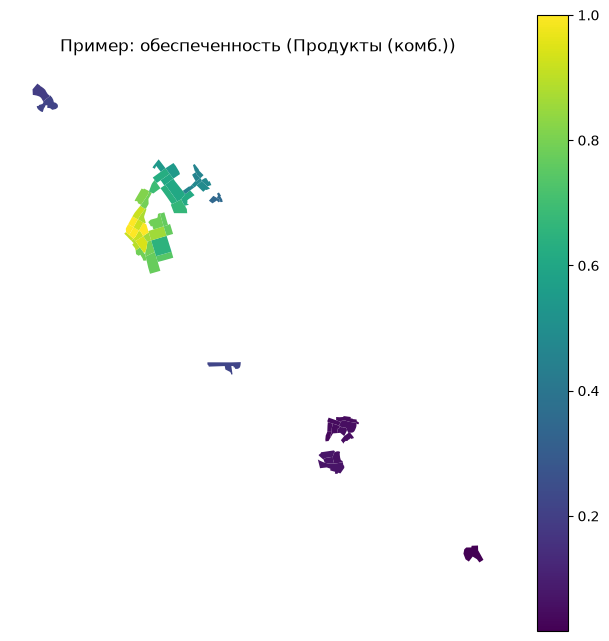

In [15]:
# ============================================================
# 12. ПРОВЕРКА
# ============================================================
def _corr(df, x, y, method="spearman"):
    sub = df[[x, y]].apply(pd.to_numeric, errors="coerce").dropna()
    if len(sub) < 3:
        return None, len(sub)
    if method == "spearman":
        value = sub[x].rank().corr(sub[y].rank())
    else:
        value = sub[x].corr(sub[y])
    return value, len(sub)

print("Кварталов:", len(blocks))
print("block_id:", results["block_id"].iloc[0], "—", results["block_id"].iloc[-1])
print("Кварталов со зданиями:", int(results["has_building"].sum()))
print("Кварталов с населением:", int(results["has_population"].sum()))
print("Матрица доступности (любая сеть):", acc_mx.shape, "->", acc_mx.shape[0], "кварталов")
print("Всего населения (оценка):", int(buildings_blocks["population"].sum()))
print()

print("Пропуски в итоговом слое:")
print(results.isna().sum().sort_values(ascending=False).head(12))
print()

for column in ("green_share", "forest_share", "park_share"):
    values = pd.to_numeric(results[column], errors="coerce").dropna()
    print(
        f"{column}: n={len(values)}, min={values.min():.3f}, "
        f"median={values.median():.3f}, max={values.max():.3f}"
    )
    out_of_range = ((values < 0) | (values > 1)).sum()
    print("  вне [0, 1]:", int(out_of_range))

print("green_share = 0:", int((results["green_share"].fillna(0) <= 0).sum()))
print("green_share = 1:", int((results["green_share"].fillna(0) >= 0.999999).sum()))
print("green_m2_per_capita: n=", int(results["green_m2_per_capita"].notna().sum()))
print("green_access_m: n=", int(results["green_access_m"].notna().sum()))
print("green_access_500 = 1:", int((results["green_access_500"].fillna(0) == 1).sum()))
print()

universes = {
    "все кварталы": pd.Series(True, index=results.index),
    "с застройкой": results["has_building"],
    "с населением": results["has_population"],
}
for name, mask in universes.items():
    subset = results.loc[mask]
    print(f"OSR ↔ green_share, {name}:")
    for method in ("spearman", "pearson"):
        value, n = _corr(subset, "osr", "green_share", method)
        print(f"  {method}: r={value if value is None else round(value, 3)}, n={n}")

weak_cols = [c for c in results.columns if c.startswith("provision_weak_")]
strong_cols = [c for c in results.columns if c.startswith("provision_strong_")]
print("provision_strong-колонок:", len(strong_cols))
print("provision_weak-колонок:", len(weak_cols))
print()

print("Средняя обеспеченность по услугам:")
for service_id, pdf in provision_results.items():
    print(f"  {SERVICE_LABELS[service_id]:<32}: {pdf['provision_strong'].mean():.2f}")

prov_cols = [c for c in results.columns if c.startswith("provision_strong_")]
if prov_cols:
    plot_col = next(
        (c for c in prov_cols if c == "provision_strong_grocery"),
        prov_cols[0],
    )
    name = SERVICE_LABELS.get(plot_col.replace("provision_strong_", ""), plot_col)
    results.plot(plot_col, legend=True, figsize=(8, 8)).set_axis_off()
    plt.title(f"Пример: обеспеченность ({name})")
    plt.show()
else:
    print("Нет рассчитанной обеспеченности для карты")


### 13. Как перезапускать ноутбук

**Полный повторный запуск (с кэшем — быстро):**
1. Активируйте окружение в PowerShell (из корня проекта): `.\\.venv\\Scripts\\Activate.ps1`
2. Запустите Jupyter: `.venv\\Scripts\\jupyter notebook`
3. Откройте `notebooks/vysokoye_research.ipynb` и выберите **Restart & Run All**.
4. Данные из `better_data` читаются всегда; результаты берутся из кэша, если он есть.

**Полный пересчёт с нуля:**
- Установите `FORCE_RECALC = True` в ячейке «0. НАСТРОЙКА» и снова **Restart & Run All**.

**Откуда берутся данные (`notebooks/better_data/`):**
- `boundaries.geojson` — границы; `blocks.geojson` — готовые кварталы;
- `building.geojson` — здания; `landuse.geojson` — функциональные зоны;
- `roads.geojson`, `railways.geojson` — дороги и ж/д;
- `lake.geojson` + `water.geojson` — вода (объединяются в один слой);
- `services/*.geojson` — сервисы и прочие городские объекты (по одному файлу на тип).

**Что сохраняется (`notebooks/data/vysokoye/`):**
- `blocks_land_use.geojson` — кварталы с землепользованием и `block_id`;
- `water_merged.geojson` — объединённый слой воды;
- `graph_drive.pickle`, `graph_walk.pickle` — дорожная и пешеходная сети;
- `accessibility_matrix_{drive,walk}_distance.csv` — расстояния по каждой сети, м;
- `accessibility_matrix_distance_any.csv` — лучшее расстояние по любой сети, м;
- `accessibility_matrix_pedestrian.csv` — итоговая пешеходная доступность, мин;
- `accessibility_matrix_drive.csv` — автомобильная доступность по `time_min`, мин;
- `graph_snap_drive.csv`, `graph_snap_walk.csv` — примыкание кварталов к графам, м;
- `buildings_blocks.geojson`, `services_blocks.geojson` — здания и сервисы по кварталам;
- `results.geojson` — итоговая таблица показателей, зелёных метрик и обеспеченности.

Этот `results.geojson` используется интерактивным HTML-дашбордом.
